In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import certifi
import requests
from io import BytesIO
from plotly import express as px
from pyjstat import pyjstat
import matplotlib.dates as mdates

In [4]:
get_url = "https://data.ssb.no/api/pxwebapi/v2/tables/11561/data?lang=no&outputFormat=json-stat2&valuecodes[ContentsCode]=EnergibalansenGWh&valuecodes[Tid]=*&valuecodes[Energibalanse]=*&codelist[Energibalanse]=vs_Energibalansepost01&valuecodes[EnergiProdukt]=*&codelist[EnergiProdukt]=vs_EnergiProdukt&heading=ContentsCode,Tid,EnergiProdukt&stub=Energibalanse"

response = requests.get(get_url)

if response.status_code == 200:
    dataset = pyjstat.Dataset.read(response.text)
    df = dataset.write("dataframe")
    print(df.head())
else:
    print(f"Feil: {response.status_code}")

                         energibalansepost    statistikkvariabel    år  \
0  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   
1  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   
2  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   
3  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   
4  1 Produksjon av primære energiprodukter  Energibalansen (GWh)  1990   

                        energiprodukt      value  
0                Alle energiprodukter  1376707.0  
1               Kull og kullprodukter     2364.0  
2                           Naturgass   275913.0  
3  Olje og oljeprodukter (ekskl. bio)   966406.0  
4                         Biobrensler     9442.0  


In [5]:
oljeindustri_forbruk = df[df.energibalansepost == '8 Eget forbruk i energiproduserende sektor']

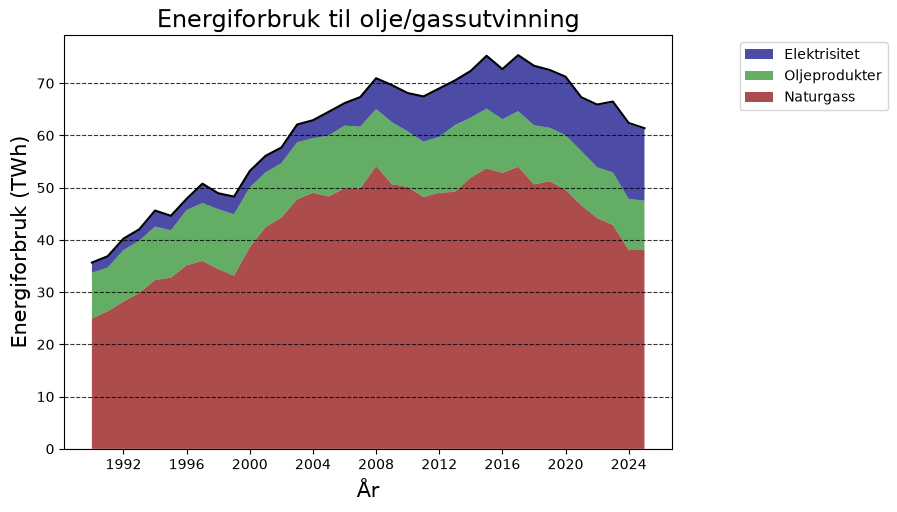

In [6]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    oljeindustri_forbruk['år'].unique().astype(int),
    oljeindustri_forbruk.loc[oljeindustri_forbruk.energiprodukt == 'Naturgass', 'value'] / 1e3,
    oljeindustri_forbruk.loc[oljeindustri_forbruk.energiprodukt == 'Olje og oljeprodukter (ekskl. bio)', 'value'] / 1e3,
    oljeindustri_forbruk.loc[oljeindustri_forbruk.energiprodukt == 'Elektrisitet', 'value'] / 1e3,
    labels=['Naturgass', 'Oljeprodukter', 'Elektrisitet'],
    colors=['darkred', 'forestgreen', 'navy'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.plot(oljeindustri_forbruk['år'].unique().astype(int), 
        oljeindustri_forbruk.loc[oljeindustri_forbruk.energiprodukt == 'Alle energiprodukter', 'value'] / 1e3, 
        color = 'black')

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Energiforbruk til olje/gassutvinning', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

# Produksjon fossile brensler

In [13]:
fossil_prod = df[df.energibalansepost == '1 Produksjon av primære energiprodukter']

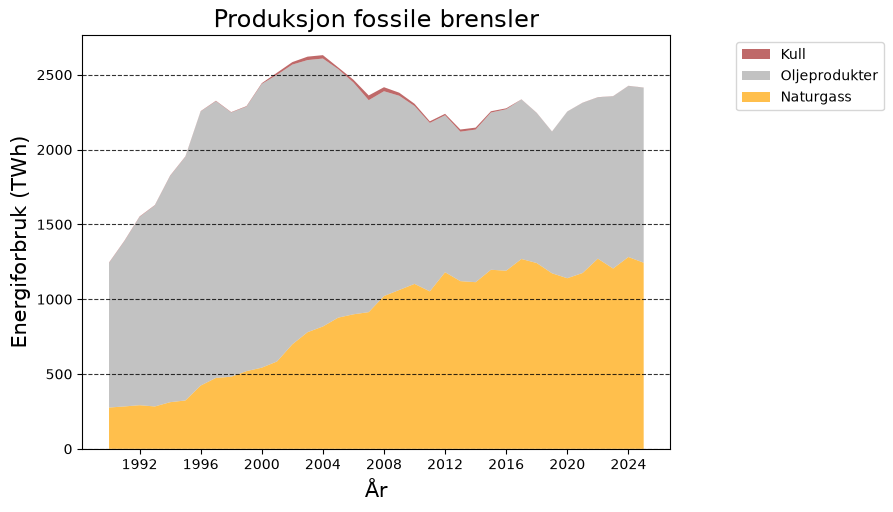

In [10]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    fossil_prod['år'].unique().astype(int),
    fossil_prod.loc[fossil_prod.energiprodukt == 'Naturgass', 'value'] / 1e3,
    fossil_prod.loc[fossil_prod.energiprodukt == 'Olje og oljeprodukter (ekskl. bio)', 'value'] / 1e3,
    fossil_prod.loc[fossil_prod.energiprodukt == 'Kull og kullprodukter', 'value'] / 1e3,
    labels=['Naturgass', 'Oljeprodukter', 'Kull'],
    colors=['orange', 'darkgrey', 'brown'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Produksjon fossile brensler', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

# Elektrisitet produksjon og forbruk

In [57]:
elektrisitet = df[df.energiprodukt == 'Elektrisitet']

In [33]:
innenlandsbruk = elektrisitet.loc[elektrisitet.energibalansepost == '6 Netto innenlands tilgang (1+2-3-4+5)','value'].to_numpy()
netto_eksport = elektrisitet.loc[elektrisitet.energibalansepost == '3 Eksport', 'value'].to_numpy() - elektrisitet.loc[elektrisitet.energibalansepost == '2 Import', 'value'].to_numpy()

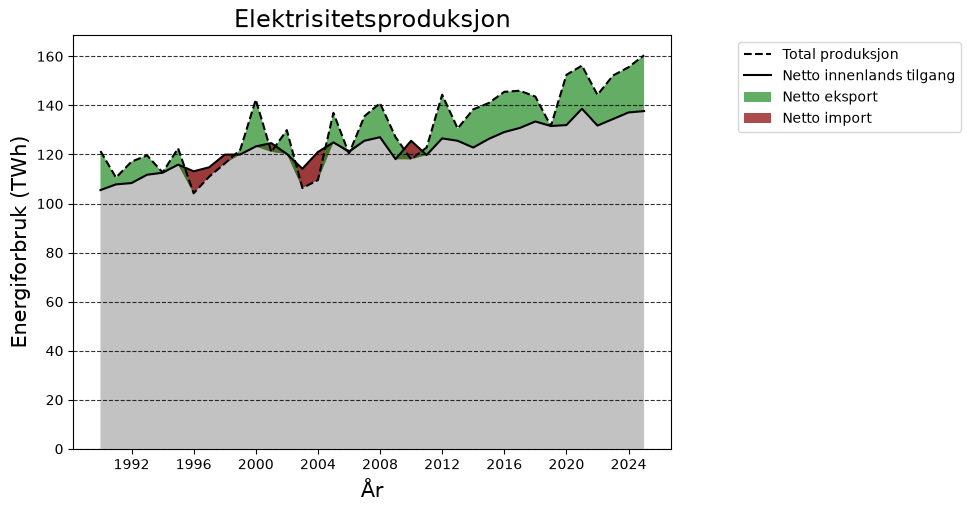

In [44]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    elektrisitet['år'].unique().astype(int),
    innenlandsbruk / 1e3,
    np.clip(netto_eksport, None , 0) / 1e3,
    np.clip(netto_eksport, 0 , None) / 1e3,
    labels=['', 'Netto import', 'Netto eksport'],
    colors=['darkgrey', 'darkred', 'forestgreen'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.plot(elektrisitet['år'].unique().astype(int), 
        elektrisitet.loc[elektrisitet.energibalansepost == '6 Netto innenlands tilgang (1+2-3-4+5)', 'value'] / 1e3,
        color = 'black',
        label = 'Netto innenlands tilgang')

ax.plot(elektrisitet['år'].unique().astype(int), 
        elektrisitet.loc[elektrisitet.energibalansepost == '1 Produksjon av primære energiprodukter', 'value'] / 1e3,
        color = 'black', linestyle= '--',
        label = 'Total produksjon')

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Elektrisitetsproduksjon', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

## Innenlands forbruk

In [45]:
andre = elektrisitet.loc[elektrisitet.energibalansepost == '12.3 Andre forbruksgrupper', 'value'].to_numpy()
industri = elektrisitet.loc[elektrisitet.energibalansepost == '12.1 Industri og bergverk', 'value'].to_numpy()
transport = elektrisitet.loc[elektrisitet.energibalansepost == '12.2 Transport', 'value'].to_numpy()
oljeproduksjon = elektrisitet.loc[elektrisitet.energibalansepost == '8 Eget forbruk i energiproduserende sektor', 'value'].to_numpy()
svinn = elektrisitet.loc[elektrisitet.energibalansepost == '7 Transformasjon', 'value'].to_numpy() + elektrisitet.loc[elektrisitet.energibalansepost == '9 Svinn', 'value'].to_numpy() + elektrisitet.loc[elektrisitet.energibalansepost == '13 Statistiske feil (6+7-8-9-10)', 'value'].to_numpy()

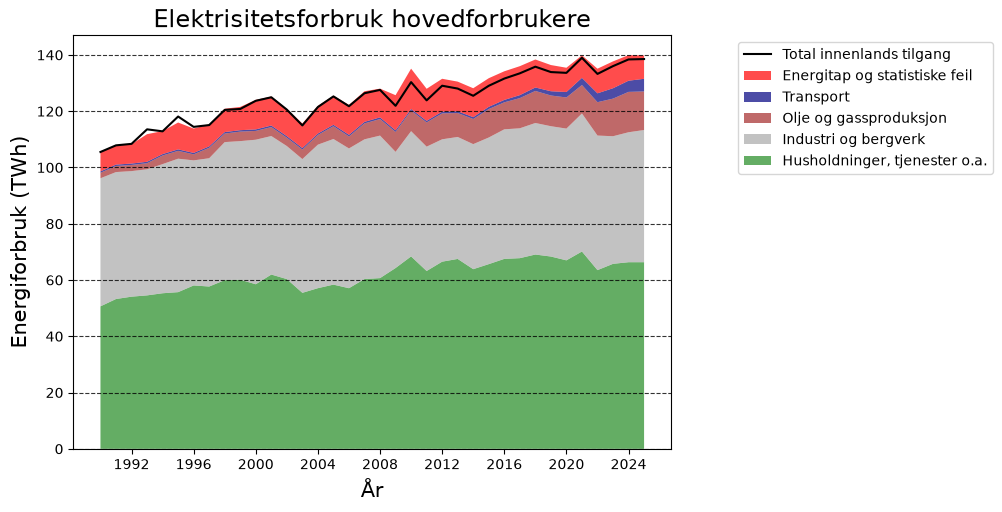

In [48]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    elektrisitet['år'].unique().astype(int),
    andre / 1e3,
    industri / 1e3,
    oljeproduksjon / 1e3,
    transport / 1e3,
    svinn / 1e3,
    labels=['Husholdninger, tjenester o.a.', 'Industri og bergverk', 'Olje og gassproduksjon', 'Transport', 'Energitap og statistiske feil'],
    colors=['forestgreen', 'darkgrey', 'brown', 'navy', 'red'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.plot(elektrisitet['år'].unique().astype(int), 
        (elektrisitet.loc[elektrisitet.energibalansepost == '6 Netto innenlands tilgang (1+2-3-4+5)', 'value'] 
        + elektrisitet.loc[elektrisitet.energibalansepost == '7 Transformasjon', 'value'].to_numpy()
        + elektrisitet.loc[elektrisitet.energibalansepost == '13 Statistiske feil (6+7-8-9-10)', 'value'].to_numpy()) / 1e3,
        color = 'black', label = 'Total innenlands tilgang')

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Elektrisitetsforbruk hovedforbrukere', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()

### Industri

In [58]:
# Mer detaljert tabell

get_url = "https://data.ssb.no/api/pxwebapi/v2/tables/11561/data?lang=no&outputFormat=json-stat2&valuecodes[ContentsCode]=EnergibalansenGWh&valuecodes[Tid]=*&valuecodes[Energibalanse]=*&codelist[Energibalanse]=vs_Energibalansepost02&valuecodes[EnergiProdukt]=*&codelist[EnergiProdukt]=vs_EnergiProdukt&heading=ContentsCode,Tid&stub=Energibalanse,EnergiProdukt"

response = requests.get(get_url)

if response.status_code == 200:
    dataset = pyjstat.Dataset.read(response.text)
    df = dataset.write("dataframe")
    print(df.head())
else:
    print(f"Feil: {response.status_code}")

                         energibalansepost         energiprodukt  \
0  1 Produksjon av primære energiprodukter  Alle energiprodukter   
1  1 Produksjon av primære energiprodukter  Alle energiprodukter   
2  1 Produksjon av primære energiprodukter  Alle energiprodukter   
3  1 Produksjon av primære energiprodukter  Alle energiprodukter   
4  1 Produksjon av primære energiprodukter  Alle energiprodukter   

     statistikkvariabel    år      value  
0  Energibalansen (GWh)  1990  1376707.0  
1  Energibalansen (GWh)  1991  1510138.0  
2  Energibalansen (GWh)  1992  1679697.0  
3  Energibalansen (GWh)  1993  1759704.0  
4  Energibalansen (GWh)  1994  1950570.0  


In [52]:
df.energibalansepost.unique()

<ArrowStringArray>
[                              '1 Produksjon av primære energiprodukter',
                                     '1.1 Av dette fra fornybare kilder',
                                        '1.1.1 Av dette i vannkraftverk',
                                        '1.1.2 Av dette i vindkraftverk',
                             '1.1.3 Av dette fra andre fornybare kilder',
                                '1.2 Av dette fra ikke fornybare kilder',
                                                              '2 Import',
                                                             '3 Eksport',
                                               '4 Internasjonal bunkers',
                                     '4.1 Internasjonal sjøfart bunkers',
                                    '4.2 Internasjonal luftfart bunkers',
                           '5 Lagerendringer (+  = nedgang, - = økning)',
                                '6 Netto innenlands tilgang (1+2-3-4+5)',
                   

In [60]:
elektrisitet = df[df.energiprodukt == 'Elektrisitet']

In [61]:
industri_total = elektrisitet.loc[elektrisitet.energibalansepost == '12.1 Industri og bergverk', 'value'].to_numpy()
jern = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.1 Produksjon av jern,stål, og ferrolegeringer', 'value'].to_numpy()
kjemisk = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.2 Produksjon av kjemiske og farmasøytiske produkter', 'value'].to_numpy()
metall = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.3 Produksjon av ikke-jernholdige metaller', 'value'].to_numpy()
mineral = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.4 Produksjon av ikke metallholdige mineralprodukter', 'value'].to_numpy()
transportmidler = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.5 Produksjon av motorvogner, tilhengere og andre transportmidler', 'value'].to_numpy()
maskiner = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.6 Produksjon av metallvarer, maskiner og utstyr', 'value'].to_numpy()
bergverk = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.7 Bergverk', 'value'].to_numpy()
næringsmidler = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.8 Produksjon av nærings- og nytelsesmidler', 'value'].to_numpy()
papir = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.9 Produksjon av papir og papirvarer, og trykking', 'value'].to_numpy()
treforedling = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.10 Treforedling', 'value'].to_numpy()
tekstiler = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.11 Produksjon av tekstiler, klær, lær og lærvarer', 'value'].to_numpy()
bygg = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.12 Bygg og anlegg', 'value'].to_numpy()
annet = elektrisitet.loc[elektrisitet.energibalansepost == '12.1.13 Annen industri', 'value'].to_numpy()

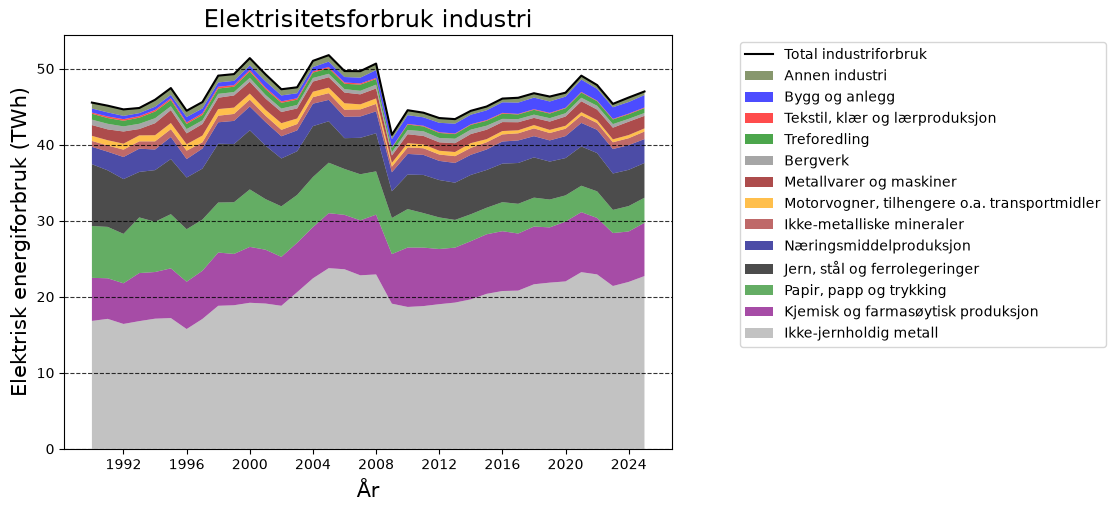

In [70]:
fig, ax = plt.subplots()

ax.set_xlabel('År', fontsize = 15)
ax.set_ylabel('Elektrisk energiforbruk (TWh)', color='black', fontsize = 15)

ax.stackplot(
    elektrisitet['år'].unique().astype(int),
    metall / 1e3,
    kjemisk / 1e3,
    papir / 1e3,
    jern / 1e3,
    næringsmidler / 1e3,
    mineral / 1e3,
    transportmidler / 1e3,
    maskiner / 1e3,
    bergverk / 1e3,
    treforedling / 1e3,
    tekstiler / 1e3,
    bygg / 1e3,
    annet / 1e3,
    labels=['Ikke-jernholdig metall', 'Kjemisk og farmasøytisk produksjon', 'Papir, papp og trykking', 'Jern, stål og ferrolegeringer', 
            'Næringsmiddelproduksjon', 'Ikke-metalliske mineraler', 'Motorvogner, tilhengere o.a. transportmidler', 'Metallvarer og maskiner',
            'Bergverk', 'Treforedling', 'Tekstil, klær og lærproduksjon', 'Bygg og anlegg', 'Annen industri'],
    colors=['darkgrey', 'purple', 'forestgreen', 'black', 'navy', 'brown', 'orange', 'darkred', 'grey', 'green', 'red', 'blue', 'darkolivegreen'],
    alpha=0.7
)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.plot(elektrisitet['år'].unique().astype(int), 
        industri_total / 1e3,
        color = 'black', label = 'Total industriforbruk')

fig.tight_layout()  
fig.set_figheight(5)
fig.set_figwidth(7)
ax.set_title('Elektrisitetsforbruk industri', fontsize = 17)
ax.legend(fontsize='medium', loc='upper left', bbox_to_anchor=(1.1, 1), reverse=True)

plt.grid(axis='y', linestyle='--', alpha=0.8, color ='black')
plt.show()